# Chapitre 11 - Cours 5 : traiter les flux, à quoi cela sert

Les cours 1 à 4 ont montré d'où viennent les flux (activité des utilisateurs, capteurs,
écritures dans une base) et comment ils sont transportés (messagerie directe, courtiers,
journaux). Reste à savoir **ce que l'on en fait**. Ce notebook couvre le début de la
section *Processing Streams* et la sous-section *Uses of Stream Processing* (*Complex
event processing*, *Stream analytics*, *Maintaining materialized views*, *Search on
streams*, *Message passing and RPC*). Le temps, les jointures et la tolérance aux
pannes sont l'objet des cours 6 et 7.

**Plan.**

1. Trois façons d'utiliser un flux ; l'opérateur de flux.
2. La détection d'événements complexes (CEP).
3. L'analytique sur flux et les algorithmes probabilistes.
4. Maintenir des vues matérialisées.
5. La recherche sur flux.
6. Flux, acteurs et RPC.

In [1]:
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Trois façons d'utiliser un flux (section *Processing Streams*)

Une fois un flux disponible, on peut :

1. **écrire** ses événements dans une base, un cache, un index, d'où d'autres clients les
   interrogeront : c'est la synchronisation des systèmes du cours 3, l'équivalent en flux
   des sorties d'un traitement par lots ;
2. **pousser** les événements vers des humains : alertes par courriel, notifications,
   tableau de bord temps réel ;
3. **transformer** un ou plusieurs flux d'entrée en un ou plusieurs flux de sortie, par
   une chaîne d'étapes qui aboutit finalement à 1 ou 2.

Le code qui fait 3 s'appelle un **opérateur** ou un **job**. Il ressemble beaucoup aux
processus Unix et aux jobs MapReduce du chapitre 10 : il lit ses entrées en
lecture seule et écrit ses sorties ailleurs, en ajout seul ; le partitionnement, la
parallélisation, les transformations et filtres élémentaires fonctionnent de la même
façon. La différence cruciale : **un flux ne se termine jamais**. On ne peut donc pas
trier l'entrée (et les jointures par tri-fusion sont exclues), et la tolérance aux pannes
change : on relance une tâche par lots de quelques minutes depuis le début, pas un job de
flux qui tourne depuis des années.

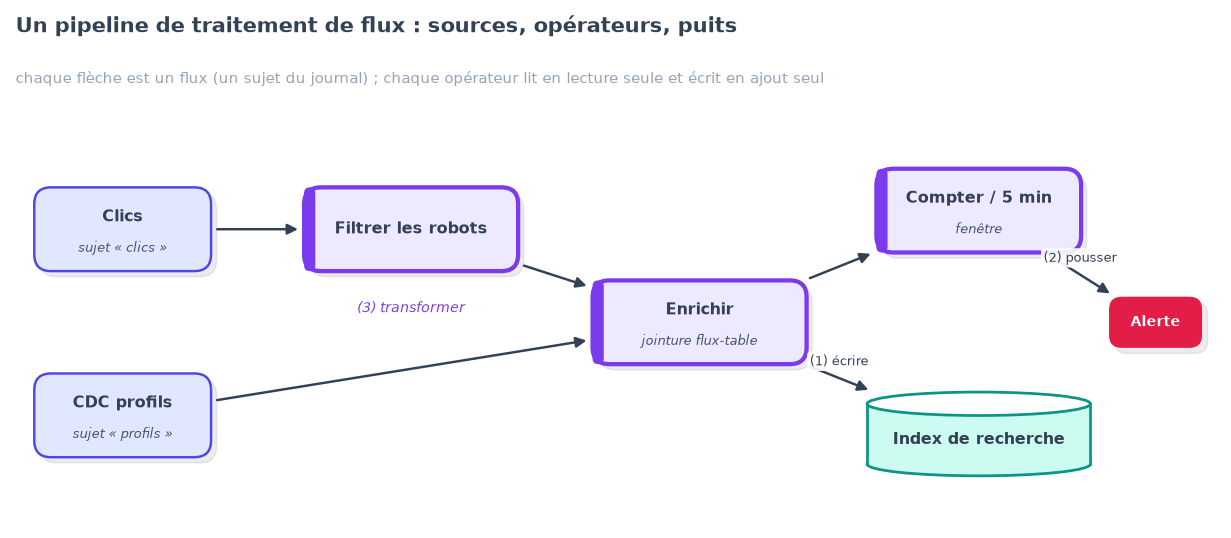

In [2]:
d = Diagram(13, 4.6, title="Un pipeline de traitement de flux : sources, opérateurs, puits",
            subtitle="chaque flèche est un flux (un sujet du journal) ; chaque opérateur lit en lecture seule et écrit en ajout seul")
d.box("s1", 1.2, 3.2, "Clics", sub="sujet « clics »", color=INDIGO, w=1.9)
d.box("s2", 1.2, 1.2, "CDC profils", sub="sujet « profils »", color=INDIGO, w=1.9)
d.box("o1", 4.3, 3.2, "Filtrer les robots", color=VIOLET, kind="model", w=2.3)
d.box("o2", 7.4, 2.2, "Enrichir", sub="jointure flux-table", color=VIOLET, kind="model", w=2.3)
d.box("o3", 10.4, 3.4, "Compter / 5 min", sub="fenêtre", color=VIOLET, kind="model", w=2.2)
d.box("k1", 10.4, 1.0, "Index de recherche", color=TEAL, kind="db", w=2.4, h=0.9)
d.box("k2", 12.3, 2.2, "Alerte", color=ROSE, kind="tag", w=1.0, h=0.55, fontsize=9)
d.arrow("s1", "o1"); d.arrow("o1", "o2"); d.arrow("s2", "o2")
d.arrow("o2", "o3"); d.arrow("o2", "k1", "(1) écrire")
d.arrow("o3", "k2", "(2) pousser")
d.note(4.3, 2.35, "(3) transformer", color=VIOLET)
d.show()

Historiquement, le traitement de flux sert surtout à la **surveillance** : détecter un
changement de comportement d'une carte bancaire volée, exécuter des ordres selon les
variations de prix d'un marché, repérer une machine défaillante dans une usine, ou, dans
le militaire et le renseignement, donner l'alarme au moindre signe d'attaque. D'autres
usages sont apparus ensuite ; les sections suivantes les passent en revue.

> **À retenir.** Un flux sert à alimenter un stockage, à notifier des humains, ou à
> produire d'autres flux par des opérateurs. Comme un job par lots, mais sans fin : ni tri
> de l'entrée, ni reprise « depuis le début ».

## 2. La détection d'événements complexes (section *Complex event processing*)

La **détection d'événements complexes** (complex event processing, CEP), née dans les
années 1990, cherche des **motifs d'événements** dans un flux, comme une expression
régulière cherche des motifs de caractères dans une chaîne. Les motifs sont décrits dans
un langage déclaratif (souvent proche de SQL) ou une interface graphique ; le moteur les
compile en **machines à états** et émet un **événement complexe** à chaque correspondance.
Les rôles de la base de données sont **inversés** : une base stocke les données et oublie
les requêtes, un moteur CEP **stocke les requêtes** (permanentes) et laisse passer les
données. Exemples : Esper, Apama, TIBCO StreamBase ; Flink et Spark Streaming offrent
aussi du SQL sur flux.

Motif classique : « au moins 5 échecs de connexion d'un même compte suivis d'un succès,
en moins d'une minute » (une attaque par force brute qui a réussi). Simulons une heure de
connexions de 500 utilisateurs, dont trois attaquants.

In [3]:
evts = []
for u in range(500):
    for t0 in rng.uniform(0, 3600, int(rng.integers(1, 4))):
        n_fautes = int(rng.choice([0, 1, 2, 3], p=[0.75, 0.17, 0.06, 0.02]))      # fautes de frappe
        t = t0
        for _ in range(n_fautes):
            evts.append((t, f"user{u}", "fail")); t += rng.uniform(4, 15)          # un humain retape lentement
        evts.append((t, f"user{u}", "ok"))
for a, t0 in [(17, 600), (231, 1800), (404, 3000)]:
    t = t0
    for _ in range(int(rng.integers(20, 40))):
        evts.append((t, f"user{a}", "fail")); t += rng.uniform(0.2, 1.0)          # un robot essaie vite
    evts.append((t, f"user{a}", "ok"))
evts.sort()
alertes = st.detect_brute_force(evts, n_fail=5, within=60)
print(f"{len(evts)} événements ; {len(alertes)} événements complexes détectés :")
pd.DataFrame(alertes, columns=["t (s)", "compte", "échecs dans la minute"]).round(1)

1446 événements ; 3 événements complexes détectés :


,t (s),compte,échecs dans la minute
0,614.0,user17,22
1,1814.3,user231,23
2,3014.9,user404,30


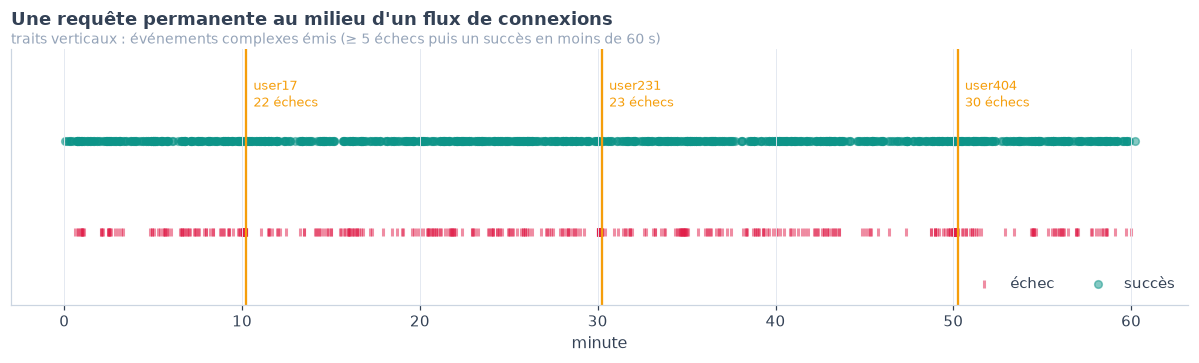

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.4))
E = pd.DataFrame(evts, columns=["t", "user", "kind"])
for kind, c, m in [("fail", ROSE, "|"), ("ok", TEAL, "o")]:
    sub = E[E.kind == kind]
    ax.scatter(sub.t / 60, np.full(len(sub), 0 if kind == "fail" else 0.25), color=c, marker=m, s=25, alpha=0.5,
               label="échec" if kind == "fail" else "succès")
for t, u, nf in alertes:
    ax.axvline(t / 60, color=AMBER, lw=1.5)
    ax.text(t / 60 + 0.4, 0.42, f"{u}\n{nf} échecs", fontsize=8.5, color=AMBER, va="top")
ax.set_yticks([]); ax.set_ylim(-0.2, 0.5)
ax.set_xlabel("minute"); ax.set_title("Une requête permanente au milieu d'un flux de connexions")
subtitle(ax, "traits verticaux : événements complexes émis (≥ 5 échecs puis un succès en moins de 60 s)")
ax.legend(loc="lower right", ncol=2)
plt.tight_layout(); plt.show()

Les trois attaques sont détectées ; les utilisateurs qui se trompent plusieurs fois mais
lentement ne déclenchent pas d'alerte, car leurs échecs sortent de la fenêtre d'une
minute (un utilisateur très maladroit pourrait toutefois en déclencher une : un motif est
toujours un compromis entre faux positifs et détections manquées). L'état du moteur est
petit : par compte, la file des instants d'échec de la dernière minute.

> **À retenir.** La CEP stocke des requêtes permanentes, compilées en machines à états, et
> laisse passer les données : c'est l'inverse d'une base de données.

## 3. L'analytique sur flux (section *Stream analytics*)

La frontière avec la CEP est floue, mais l'**analytique sur flux** s'intéresse moins à
des séquences précises qu'à des **agrégats et statistiques** sur de grands volumes :
fréquence d'un type d'événement par intervalle, moyenne glissante d'une valeur,
comparaison avec la même période de la semaine précédente pour détecter une tendance ou
une anomalie. Ces statistiques sont calculées sur des intervalles de temps, des
**fenêtres** (cours 6) : moyenner sur quelques minutes lisse les fluctuations d'une
seconde à l'autre tout en restant réactif.

Ces systèmes emploient souvent des **algorithmes probabilistes** : filtres de Bloom pour
l'appartenance à un ensemble (chapitre 3), **HyperLogLog** pour compter les
éléments distincts, estimateurs de percentiles (chapitre 1). Ils donnent
un résultat approché avec beaucoup moins de mémoire. Exemple : compter les visiteurs
distincts d'un site. Un ensemble exact garde chaque identifiant ; HyperLogLog garde $2^p$
petits registres, quel que soit le nombre de visiteurs, pour une erreur relative typique
de $1{,}04/\sqrt{2^p}$.

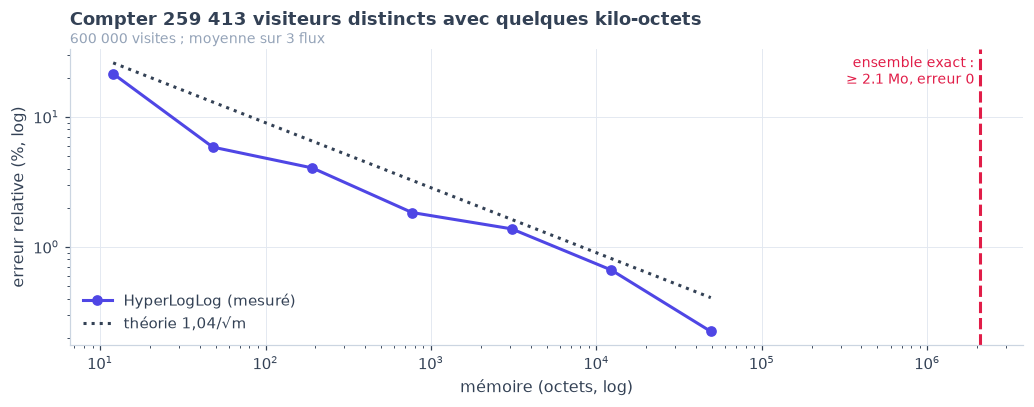

,registres,mémoire (octets),erreur relative mesurée,erreur théorique
p,,,,
4,16,12,0.214,0.260
6,64,48,0.059,0.130
8,256,192,0.040,0.065
10,1024,768,0.018,0.033
12,4096,3072,0.014,0.016
14,16384,12288,0.007,0.008
16,65536,49152,0.002,0.004


In [5]:
n_distincts, n_visites = 300_000, 600_000
flux_par_graine = {}
for s in range(3):                                         # hachage une fois par flux, réutilisé pour chaque p
    flux = np.random.default_rng(100 + s).integers(0, n_distincts, n_visites)
    flux_par_graine[s] = (np.array([st.hash64(f"{s}-{v}") for v in flux], dtype=np.uint64), len(np.unique(flux)))
rows = []
for p in (4, 6, 8, 10, 12, 14, 16):
    errs = []
    for s, (hachages, vrai) in flux_par_graine.items():
        h = st.HyperLogLog(p)
        h.add_hashes(hachages)
        errs.append(abs(h.count() - vrai) / vrai)
    rows.append({"p": p, "registres": 2 ** p, "mémoire (octets)": st.HyperLogLog(p).memory_bytes,
                 "erreur relative mesurée": np.mean(errs), "erreur théorique": 1.04 / np.sqrt(2 ** p)})
H = pd.DataFrame(rows).set_index("p")
exact_octets = vrai * 8                                    # borne basse : 8 octets par identifiant haché
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(H["mémoire (octets)"], H["erreur relative mesurée"] * 100, "o-", color=INDIGO, label="HyperLogLog (mesuré)")
ax.plot(H["mémoire (octets)"], H["erreur théorique"] * 100, ":", color=SLATE, label="théorie 1,04/√m")
ax.axvline(exact_octets, color=ROSE, ls="--")
ax.text(exact_octets * 0.93, 18, f"ensemble exact :\n≥ {exact_octets / 1e6:.1f} Mo, erreur 0", color=ROSE, ha="right", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("mémoire (octets, log)"); ax.set_ylabel("erreur relative (%, log)")
ax.set_title(f"Compter {vrai:,} visiteurs distincts avec quelques kilo-octets".replace(",", " "))
subtitle(ax, f"{n_visites:,}".replace(",", " ") + " visites ; moyenne sur 3 flux")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()
H.round(4)

L'erreur suit la loi en $1/\sqrt{m}$ (à la variance près des trois flux) : avec 12 Kio
($p = 14$), elle est de l'ordre de 1 %, pour un ensemble exact qui demanderait au moins
2 Mo (et bien plus en pratique) ; surtout, la mémoire de
HyperLogLog ne dépend pas du nombre de visiteurs, et deux esquisses se **fusionnent**
(maximum registre par registre), ce qui permet d'agréger des partitions ou des fenêtres.
Attention à un contresens fréquent : le traitement de flux n'est **pas** intrinsèquement
approximatif. Les algorithmes probabilistes ne sont qu'une **optimisation** ; on peut
toujours calculer exactement si l'on accepte d'y mettre la mémoire.

Les frameworks open source de traitement de flux distribué, comme Apache Storm, Spark
Streaming, Flink, Samza et Kafka Streams, sont conçus avec l'analytique en tête ;
Google Cloud Dataflow et Azure Stream Analytics en sont des versions hébergées.

> **À retenir.** L'analytique sur flux calcule des agrégats sur des fenêtres ; les
> algorithmes probabilistes (Bloom, HyperLogLog, estimateurs de percentiles) économisent
> la mémoire, mais ne sont qu'une optimisation.